# **setup e dados**

In [1]:
import pandas as pd
import os
# No Colab: envie o CSV para /content. Rodando local: deixe o arquivo em data/accident_data.csv
csv = "/content/accident_data.csv" if os.path.exists("/content/accident_data.csv") else "../data/accident_data.csv"
if not os.path.exists(csv):
    csv = "data/accident_data.csv"

df = pd.read_csv(csv)
df["Accident Date"] = pd.to_datetime(df["Accident Date"], errors="coerce", dayfirst=True)

print(df.shape)
df.info(memory_usage="deep")
print(df.isna().sum())

print(df["Accident_Severity"].value_counts(normalize=True))
print(df["Accident Date"].min(), df["Accident Date"].max(),
      "datas inválidas:", df["Accident Date"].isna().sum())
print(df[["Latitude", "Longitude"]].describe())

cats = ["Light_Conditions", "Road_Surface_Conditions", "Road_Type",
        "Urban_or_Rural_Area", "Weather_Conditions", "Vehicle_Type"]
for c in cats:
    print(df[c].value_counts(dropna=False).head(10), "\n")

print("distritos:", df["District Area"].nunique())
print("linhas duplicadas:", df.duplicated().sum())

(670679, 14)


<class 'pandas.DataFrame'>
RangeIndex: 670679 entries, 0 to 670678
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   Index                    670679 non-null  str           
 1   Accident_Severity        670679 non-null  str           
 2   Accident Date            670679 non-null  datetime64[us]
 3   Latitude                 670654 non-null  float64       
 4   Light_Conditions         670679 non-null  str           
 5   District Area            670679 non-null  str           
 6   Longitude                670653 non-null  float64       
 7   Number_of_Casualties     670679 non-null  int64         
 8   Number_of_Vehicles       670679 non-null  int64         
 9   Road_Surface_Conditions  669937 non-null  str           
 10  Road_Type                666099 non-null  str           
 11  Urban_or_Rural_Area      670664 non-null  str           
 12  Weather_Conditions       65

Road_Type
Single carriageway    499607
Dual carriageway      100926
Roundabout             44654
One way street         13769
Slip road               7143
NaN                     4580
Name: count, dtype: int64 

Urban_or_Rural_Area
Urban          428038
Rural          242615
NaN                15
Unallocated        11
Name: count, dtype: int64 

Weather_Conditions
Fine no high winds       528789
Raining no high winds     80893
Other                     17386
NaN                       14351
Raining + high winds       9755
Fine + high winds          8695
Snowing no high winds      6340
Fog or mist                3575
Snowing + high winds        895
Name: count, dtype: int64 

Vehicle_Type
Car                                      505502
Van / Goods 3.5 tonnes mgw or under       34689
Bus or coach (17 or more pass seats)      26279
Motorcycle over 500cc                     26036
Goods 7.5 tonnes mgw and over             17579
Motorcycle 125cc and under                15493
Taxi/Private hir

linhas duplicadas: 19


# **Auditoria de dados**

In [2]:
print(df.shape)
print("Index único?", df["Index"].is_unique, "| repetidos:", df["Index"].duplicated().sum())

print(df["Accident_Severity"].value_counts(normalize=True))
print(df["Accident Date"].min(), df["Accident Date"].max(),
      "datas inválidas:", df["Accident Date"].isna().sum())

print(df[["Latitude", "Longitude"]].describe())
print(df.isna().sum())

print("tipos de veículo:", df["Vehicle_Type"].nunique())
print(df["Light_Conditions"].value_counts(dropna=False))
print(df[["Number_of_Casualties", "Number_of_Vehicles"]].describe())

(670679, 14)
Index único? False | repetidos: 239659
Accident_Severity
Slight     0.853325
Serious    0.133548
Fatal      0.013127
Name: proportion, dtype: float64
2019-01-01 00:00:00 2025-12-31 00:00:00 datas inválidas: 0
            Latitude      Longitude
count  670654.000000  670653.000000
mean       52.554015      -1.431468
std         1.406956       1.383224
min        49.914430      -7.516225
25%        51.490672      -2.332413
50%        52.316381      -1.411817
75%        53.453395      -0.233365
max        60.757544       1.762010


Index                          0
Accident_Severity              0
Accident Date                  0
Latitude                      25
Light_Conditions               0
District Area                  0
Longitude                     26
Number_of_Casualties           0
Number_of_Vehicles             0
Road_Surface_Conditions      742
Road_Type                   4580
Urban_or_Rural_Area           15
Weather_Conditions         14351
Vehicle_Type                   0
dtype: int64
tipos de veículo: 16
Light_Conditions
Daylight                       492201
Darkness - lights lit          131333
Darkness - no lighting          37981
Darkness - lighting unknown      6583
Darkness - lights unlit          2581
Name: count, dtype: int64
       Number_of_Casualties  Number_of_Vehicles
count         670679.000000       670679.000000
mean               1.357013            1.831237
std                0.824759            0.715443
min                1.000000            1.000000
25%                1.000000    

In [3]:
g = df.groupby("Index")
campos = ["Accident_Severity", "Accident Date", "Latitude", "Longitude",
          "Light_Conditions", "Weather_Conditions", "Road_Type",
          "Number_of_Casualties", "Number_of_Vehicles"]
for c in campos:
    print(c, "-> Index com valores conflitantes:", (g[c].nunique(dropna=False) > 1).sum())

print("acidentes únicos:", df["Index"].nunique())
print(g.size().describe())

acc = df.drop_duplicates("Index")
print(acc.groupby(acc["Accident Date"].dt.year).size())
print(acc.groupby(acc["Accident Date"].dt.month).size())
print(pd.crosstab(acc["Accident Date"].dt.year, acc["Accident_Severity"],
                  normalize="index").round(3))

Accident_Severity -> Index com valores conflitantes: 46
Accident Date -> Index com valores conflitantes: 131
Latitude -> Index com valores conflitantes: 131
Longitude -> Index com valores conflitantes: 131
Light_Conditions -> Index com valores conflitantes: 63
Weather_Conditions -> Index com valores conflitantes: 65
Road_Type -> Index com valores conflitantes: 84
Number_of_Casualties -> Index com valores conflitantes: 70


Number_of_Vehicles -> Index com valores conflitantes: 77
acidentes únicos: 431020
count    431020.000000
mean          1.556028
std         364.766628
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max      239478.000000
dtype: float64
Accident Date
2019    115942
2020    107523
2021    102846
2022     94709
2023      3443
2024      3352
2025      3205
dtype: int64
Accident Date
1     34502
2     32361
3     35534
4     33799
5     36819
6     36835
7     37487
8     34750
9     36836
10    39013
11    39250
12    33834
dtype: int64
Accident_Severity  Fatal  Serious  Slight
Accident Date                            
2019               0.014    0.133   0.853
2020               0.013    0.133   0.854
2021               0.012    0.131   0.857
2022               0.010    0.129   0.862
2023               0.016    0.133   0.851
2024               0.013    0.130   0.857
2025               0.015    0.142   0.843


In [4]:
vc = df["Index"].value_counts()
top = vc.index[0]
print("Index gigante:", repr(top), vc.iloc[0])

big  = df[df["Index"] == top]
rest = df[df["Index"] != top]
print(big.head())

for nome, parte in [("gigante", big), ("resto", rest)]:
    print("\n==", nome, len(parte))
    print(parte["Accident Date"].dt.year.value_counts().sort_index())
    print(parte["Accident_Severity"].value_counts(normalize=True).round(3))
    print("sem coordenadas:", parte["Latitude"].isna().sum())

mask = df["Accident Date"].dt.year >= 2023
print("\nlinhas com data >= 2023:", mask.sum())
print("dessas, no Index gigante:", (mask & (df["Index"] == top)).sum())

Index gigante: '2.01E+12' 239478
          Index Accident_Severity Accident Date   Latitude  \
23265  2.01E+12           Serious    2019-01-02  54.118079   
23266  2.01E+12            Slight    2019-01-03  54.226916   
23267  2.01E+12            Slight    2019-01-04  54.344991   
23268  2.01E+12            Slight    2019-01-05  54.330220   
23269  2.01E+12            Slight    2019-01-05  54.260714   

            Light_Conditions      District Area  Longitude  \
23265  Darkness - lights lit  Barrow-in-Furness  -3.227114   
23266               Daylight     South Lakeland  -2.773521   
23267               Daylight     South Lakeland  -2.777121   
23268               Daylight     South Lakeland  -2.739167   
23269               Daylight     South Lakeland  -2.813915   

       Number_of_Casualties  Number_of_Vehicles Road_Surface_Conditions  \
23265                     1                   1                     Dry   
23266                     1                   2             Wet or damp

### Datas deslocadas em 12 anos
Nas linhas em que o `Index` não foi corrompido, ele segue o padrão do STATS19 (dados oficiais do
Reino Unido), que começa com o **ano real** do acidente. Cruzando esse ano com a data do dataset,
cada ano aparece somado de 12: 2007 → 2019, 2008 → 2020, 2009 → 2021 e 2010 → 2022.
O dia da semana confirma: com a data do dataset, o pico de acidentes cai no sábado e o mínimo na
segunda; voltando 12 anos, o pico vai para a sexta e o mínimo para o domingo, que é o padrão
conhecido do trânsito britânico. Por isso o dia da semana é calculado na data real.

In [5]:
idx = df["Index"].astype(str)
normal = idx.str.match(r"^\d{4}[0-9A-Z]{2}")
print("Index no formato STATS19:", normal.sum(), "| corrompido:", (~normal).sum())
print(pd.crosstab(idx[normal].str[:4].rename("ano no Index"),
                  df.loc[normal, "Accident Date"].dt.year.rename("ano na data")))

base = df[df["Accident Date"].dt.year < 2023]
print("\nAcidentes por dia da semana, data do dataset:")
print(base["Accident Date"].dt.day_name().value_counts())
print("\nAcidentes por dia da semana, data real (-12 anos):")
print((base["Accident Date"] - pd.DateOffset(years=12)).dt.day_name().value_counts())

Index no formato STATS19: 430776 | corrompido: 239903
ano na data     2019    2020    2021   2022  2023  2024  2025
ano no Index                                                 
2007          115818       0       0      0     0     0     0
2008               0  107462       0      0     0     0     0
2009               0       0  102814      0     0     0     0
2010               0       0       0  94682     0     0     0
2023               0       0       0      0  3443     0     0
2024               0       0       0      0     0  3352     0
2025               0       0       0      0     0     0  3205

Acidentes por dia da semana, data do dataset:


Accident Date
Saturday     107178
Wednesday     99558
Thursday      99511
Friday        97900
Tuesday       94550
Sunday        89302
Monday        72680
Name: count, dtype: int64

Acidentes por dia da semana, data real (-12 anos):
Accident Date
Friday       107178
Tuesday       99558
Wednesday     99511
Thursday      97900
Monday        94550
Saturday      89302
Sunday        72680
Name: count, dtype: int64


#**Limpeza**

In [6]:
# Remove o Index (corrompido pelo Excel) e linhas totalmente repetidas
d = df.drop(columns=["Index"]).drop_duplicates()
print("após remover Index e duplicatas:", len(d))

# Remove 2023-2025 (bloco de 10.000 linhas suspeito)
d = d[d["Accident Date"] < "2023-01-01"].copy()
print("após remover 2023-2025:", len(d))

# Remove linhas sem coordenadas
d = d.dropna(subset=["Latitude", "Longitude"])
print("após remover sem coordenadas:", len(d))

# Nulos categóricos viram "Unknown"
CATS = ["Light_Conditions", "Road_Surface_Conditions", "Road_Type",
        "Urban_or_Rural_Area", "Weather_Conditions", "Vehicle_Type", "District Area"]
for c in CATS:
    d[c] = d[c].fillna("Unknown")
d["Urban_or_Rural_Area"] = d["Urban_or_Rural_Area"].replace("Unallocated", "Unknown")

# Alvo numérico: 0 = leve, 1 = grave, 2 = fatal
d["y"] = d["Accident_Severity"].map({"Slight": 0, "Serious": 1, "Fatal": 2}).astype("int8")
d = d.reset_index(drop=True)

print("\nnulos restantes:", d.isna().sum().sum())
print(d["y"].value_counts(normalize=True).round(4))

após remover Index e duplicatas: 670627
após remover 2023-2025: 660627


após remover sem coordenadas: 660601



nulos restantes: 0
y
0    0.8534
1    0.1335
2    0.0131
Name: proportion, dtype: float64


#**Features e divisão**

In [7]:
import numpy as np
from sklearn.model_selection import train_test_split

# Features de data (só temos a data, não a hora do acidente)
# O dia da semana é calculado na data REAL (data do dataset - 12 anos, ver auditoria);
# com a data do dataset ele ficaria deslocado em 1 dia. O mês não muda.
dt = d["Accident Date"].dt
dow = (d["Accident Date"] - pd.DateOffset(years=12)).dt.dayofweek
d["month_sin"] = np.sin(2 * np.pi * dt.month / 12)
d["month_cos"] = np.cos(2 * np.pi * dt.month / 12)
d["dow_sin"]   = np.sin(2 * np.pi * dow / 7)
d["dow_cos"]   = np.cos(2 * np.pi * dow / 7)
d["is_weekend"] = (dow >= 5).astype("int8")

# Divisão 70/15/15, estratificada pela gravidade
train, temp = train_test_split(d, test_size=0.30, stratify=d["y"], random_state=42)
val, test   = train_test_split(temp, test_size=0.50, stratify=temp["y"], random_state=42)

print(len(train), len(val), len(test))
for nome, p in [("treino", train), ("validação", val), ("teste", test)]:
    print(nome, p["y"].value_counts().sort_index().tolist(),
          p["y"].value_counts(normalize=True).round(4).tolist())

462420 99090 99091
treino [394609, 61748, 6063] [0.8534, 0.1335, 0.0131]
validação [84559, 13232, 1299] [0.8534, 0.1335, 0.0131]
teste [84560, 13232, 1299] [0.8534, 0.1335, 0.0131]


In [8]:
CATS = ["Light_Conditions", "Road_Surface_Conditions", "Road_Type",
        "Urban_or_Rural_Area", "Weather_Conditions", "Vehicle_Type", "District Area"]
NUM  = ["Latitude", "Longitude", "month_sin", "month_cos",
        "dow_sin", "dow_cos", "is_weekend"]

# Vocabulário aprendido SÓ no treino. Código 0 = categoria nunca vista.
maps = {c: {v: i + 1 for i, v in enumerate(sorted(train[c].unique()))} for c in CATS}

# Média e desvio das coordenadas, também só do treino
mu = train[["Latitude", "Longitude"]].mean()
sd = train[["Latitude", "Longitude"]].std()

def preparar(part):
    X_cat = np.stack([part[c].map(maps[c]).fillna(0).astype("int32").to_numpy()
                      for c in CATS], axis=1)
    X_num = part[NUM].copy()
    X_num[["Latitude", "Longitude"]] = (X_num[["Latitude", "Longitude"]] - mu) / sd
    return X_cat, X_num.to_numpy("float32"), part["y"].to_numpy()

Xc_tr, Xn_tr, y_tr = preparar(train)
Xc_va, Xn_va, y_va = preparar(val)
Xc_te, Xn_te, y_te = preparar(test)

print("categóricas:", Xc_tr.shape, "| numéricas:", Xn_tr.shape)
print({c: len(maps[c]) + 1 for c in CATS})   # tamanho de cada vocabulário
print("categorias desconhecidas (val/teste):", (Xc_va == 0).sum(), (Xc_te == 0).sum())

categóricas: (462420, 7) | numéricas: (462420, 7)
{'Light_Conditions': 6, 'Road_Surface_Conditions': 7, 'Road_Type': 7, 'Urban_or_Rural_Area': 4, 'Weather_Conditions': 10, 'Vehicle_Type': 17, 'District Area': 423}
categorias desconhecidas (val/teste): 0 0


#**Experimentos iniciais**
(o recall fraco da classe Fatal motivou a mudança pra binário).

In [9]:
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, average_precision_score)

NOMES = ["Leve", "Grave", "Fatal"]

def avaliar(y_true, y_pred, y_proba=None, titulo=""):
    print(f"=== {titulo} ===")
    print("acurácia:", round(accuracy_score(y_true, y_pred), 4))
    print("F1 macro:", round(f1_score(y_true, y_pred, average="macro"), 4))
    print(classification_report(y_true, y_pred, target_names=NOMES, digits=3, zero_division=0))
    print("matriz de confusão (linhas = real, colunas = previsto):")
    print(confusion_matrix(y_true, y_pred))
    if y_proba is not None:
        ap = [average_precision_score(y_true == k, y_proba[:, k]) for k in range(3)]
        print("PR-AUC (leve/grave/fatal):", np.round(ap, 4))

# Baseline trivial: sempre responde "Leve"
prior = np.bincount(y_tr) / len(y_tr)
pred_dummy  = np.zeros(len(y_va), dtype=int)
proba_dummy = np.tile(prior, (len(y_va), 1))

avaliar(y_va, pred_dummy, proba_dummy, "Baseline trivial: sempre 'Leve' (validação)")

=== Baseline trivial: sempre 'Leve' (validação) ===
acurácia: 0.8534
F1 macro: 0.307
              precision    recall  f1-score   support

        Leve      0.853     1.000     0.921     84559
       Grave      0.000     0.000     0.000     13232
       Fatal      0.000     0.000     0.000      1299

    accuracy                          0.853     99090
   macro avg      0.284     0.333     0.307     99090
weighted avg      0.728     0.853     0.786     99090

matriz de confusão (linhas = real, colunas = previsto):
[[84559     0     0]
 [13232     0     0]
 [ 1299     0     0]]
PR-AUC (leve/grave/fatal): [0.8534 0.1335 0.0131]


In [10]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack, csr_matrix
import time

# One-hot das categóricas (ajustado só no treino) + numéricas
ohe = OneHotEncoder(handle_unknown="ignore")
Xc_tr_oh = ohe.fit_transform(Xc_tr)
Xc_va_oh = ohe.transform(Xc_va)

X_tr_lr = hstack([Xc_tr_oh, csr_matrix(Xn_tr)]).tocsr()
X_va_lr = hstack([Xc_va_oh, csr_matrix(Xn_va)]).tocsr()
print("matriz de treino:", X_tr_lr.shape)

t0 = time.time()
lr = LogisticRegression(class_weight="balanced", max_iter=300)
lr.fit(X_tr_lr, y_tr)
print("tempo de treino:", round(time.time() - t0), "s")

proba_lr = lr.predict_proba(X_va_lr)
avaliar(y_va, proba_lr.argmax(axis=1), proba_lr,
        "Regressão logística, class_weight balanced (validação)")

matriz de treino: (462420, 474)


tempo de treino: 13 s
=== Regressão logística, class_weight balanced (validação) ===
acurácia: 0.4724
F1 macro: 0.2993
              precision    recall  f1-score   support

        Leve      0.891     0.498     0.639     84559
       Grave      0.161     0.301     0.209     13232
       Fatal      0.026     0.538     0.049      1299

    accuracy                          0.472     99090
   macro avg      0.359     0.446     0.299     99090
weighted avg      0.782     0.472     0.574     99090

matriz de confusão (linhas = real, colunas = previsto):
[[42128 20505 21926]
 [ 4834  3979  4419]
 [  326   274   699]]
PR-AUC (leve/grave/fatal): [0.893  0.151  0.0305]


In [11]:
# !pip install -q lightgbm    # só se o import falhar
import lightgbm as lgb
import pandas as pd

def para_gb(Xc, Xn):
    X = pd.DataFrame(Xn, columns=NUM)
    for i, c in enumerate(CATS):
        X[c] = pd.Categorical(Xc[:, i], categories=range(len(maps[c]) + 1))
    return X[CATS + NUM]

X_tr_gb, X_va_gb = para_gb(Xc_tr, Xn_tr), para_gb(Xc_va, Xn_va)

t0 = time.time()
gb = lgb.LGBMClassifier(objective="multiclass", n_estimators=300, learning_rate=0.05,
                        num_leaves=31, class_weight="balanced",
                        random_state=42, n_jobs=-1, verbose=-1)
gb.fit(X_tr_gb, y_tr)
print("tempo de treino:", round(time.time() - t0), "s")

proba_gb = gb.predict_proba(X_va_gb)
avaliar(y_va, proba_gb.argmax(axis=1), proba_gb, "LightGBM, class_weight balanced (validação)")

tempo de treino: 24 s


=== LightGBM, class_weight balanced (validação) ===
acurácia: 0.5162
F1 macro: 0.3144
              precision    recall  f1-score   support

        Leve      0.886     0.547     0.676     84559
       Grave      0.162     0.334     0.218     13232
       Fatal      0.026     0.395     0.049      1299

    accuracy                          0.516     99090
   macro avg      0.358     0.425     0.314     99090
weighted avg      0.778     0.516     0.607     99090

matriz de confusão (linhas = real, colunas = previsto):
[[46218 22540 15801]
 [ 5543  4422  3267]
 [  418   368   513]]
PR-AUC (leve/grave/fatal): [0.8895 0.1544 0.0274]


#**Binário (grave/fatal vs. leve)**

In [12]:
from sklearn.metrics import roc_auc_score

# Alvo binário: 1 = grave ou fatal, 0 = leve
yb_tr, yb_va, yb_te = (y_tr >= 1).astype(int), (y_va >= 1).astype(int), (y_te >= 1).astype(int)
print("proporção de graves/fatais (treino/val/teste):",
      yb_tr.mean().round(4), yb_va.mean().round(4), yb_te.mean().round(4))

def captura_topk_bin(y_true, score, frac):
    k = int(len(score) * frac)
    idx = np.argsort(-score)[:k]
    return y_true[idx].sum() / y_true.sum()

def avaliar_bin(y_true, score, titulo=""):
    print(f"=== {titulo} ===")
    print("PR-AUC:", round(average_precision_score(y_true, score), 4),
          "| ROC-AUC:", round(roc_auc_score(y_true, score), 4))
    for f in (0.10, 0.20, 0.30):
        c = captura_topk_bin(y_true, score, f)
        print(f"  top {int(f*100)}% de maior risco captura {c:.1%} dos graves/fatais (lift {c/f:.2f}x)")

# Referência: pontuação aleatória (acaso)
score_acaso = np.random.default_rng(42).random(len(yb_va))
avaliar_bin(yb_va, score_acaso, "Acaso (validação)")

# Regressão logística binária
lr_bin = LogisticRegression(class_weight="balanced", max_iter=300)
lr_bin.fit(X_tr_lr, yb_tr)
score_lr_bin = lr_bin.predict_proba(X_va_lr)[:, 1]
avaliar_bin(yb_va, score_lr_bin, "Regressão logística binária (validação)")

proporção de graves/fatais (treino/val/teste): 0.1466 0.1466 0.1466
=== Acaso (validação) ===
PR-AUC: 0.1465 | ROC-AUC: 0.4971
  top 10% de maior risco captura 9.9% dos graves/fatais (lift 0.99x)
  top 20% de maior risco captura 19.9% dos graves/fatais (lift 1.00x)
  top 30% de maior risco captura 29.9% dos graves/fatais (lift 1.00x)


=== Regressão logística binária (validação) ===
PR-AUC: 0.2132 | ROC-AUC: 0.6127
  top 10% de maior risco captura 17.8% dos graves/fatais (lift 1.78x)
  top 20% de maior risco captura 31.3% dos graves/fatais (lift 1.56x)
  top 30% de maior risco captura 43.0% dos graves/fatais (lift 1.43x)


In [13]:
gb_bin = lgb.LGBMClassifier(objective="binary", n_estimators=300, learning_rate=0.05,
                            num_leaves=31, class_weight="balanced",
                            random_state=42, n_jobs=-1, verbose=-1)
gb_bin.fit(X_tr_gb, yb_tr)
score_gb_bin = gb_bin.predict_proba(X_va_gb)[:, 1]
avaliar_bin(yb_va, score_gb_bin, "LightGBM binário (validação)")

# Tabela comparativa (vai crescer quando entrar a rede neural)
scores_bin = {"Acaso": score_acaso,
              "Regressão logística": score_lr_bin,
              "LightGBM": score_gb_bin}
res_bin = pd.DataFrame({
    nome: {"PR-AUC": average_precision_score(yb_va, s),
           "ROC-AUC": roc_auc_score(yb_va, s),
           "Captura top 10%": captura_topk_bin(yb_va, s, 0.10),
           "Captura top 20%": captura_topk_bin(yb_va, s, 0.20),
           "Captura top 30%": captura_topk_bin(yb_va, s, 0.30)}
    for nome, s in scores_bin.items()
}).T.round(4)
res_bin

=== LightGBM binário (validação) ===
PR-AUC: 0.2085 | ROC-AUC: 0.6068
  top 10% de maior risco captura 17.4% dos graves/fatais (lift 1.74x)
  top 20% de maior risco captura 30.9% dos graves/fatais (lift 1.54x)
  top 30% de maior risco captura 42.2% dos graves/fatais (lift 1.41x)


,PR-AUC,ROC-AUC,Captura top 10%,Captura top 20%,Captura top 30%
Acaso,0.1465,0.4971,0.0992,0.1993,0.2985
Regressão logística,0.2132,0.6127,0.1781,0.3126,0.4304
LightGBM,0.2085,0.6068,0.1744,0.3087,0.4221


#**Rede Neural**

In [14]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
torch.manual_seed(42)

def tensores(Xc, Xn, yb):
    return (torch.tensor(Xc, dtype=torch.long),
            torch.tensor(Xn, dtype=torch.float32),
            torch.tensor(yb, dtype=torch.float32))

dl_tr = DataLoader(TensorDataset(*tensores(Xc_tr, Xn_tr, yb_tr)), batch_size=1024, shuffle=True)
dl_va = DataLoader(TensorDataset(*tensores(Xc_va, Xn_va, yb_va)), batch_size=4096)

VOCAB = [len(maps[c]) + 1 for c in CATS]     # inclui o código 0 (categoria desconhecida)
def dim_emb(n): return min(16, (n + 1) // 2)  # regra prática para o tamanho do embedding

class RedeAcidentes(nn.Module):
    def __init__(self, vocab, n_num, ocultas=(128, 64), dropout=0.3):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, dim_emb(n)) for n in vocab])
        d_in = sum(dim_emb(n) for n in vocab) + n_num
        camadas = []
        for h in ocultas:
            camadas += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(dropout)]
            d_in = h
        camadas.append(nn.Linear(d_in, 1))
        self.mlp = nn.Sequential(*camadas)

    def forward(self, xc, xn):
        e = [emb(xc[:, i]) for i, emb in enumerate(self.embs)]
        return self.mlp(torch.cat(e + [xn], dim=1)).squeeze(1)   # devolve o logit

@torch.no_grad()
def prever(modelo, dl):
    modelo.eval()
    out = [torch.sigmoid(modelo(xc.to(device), xn.to(device))).cpu() for xc, xn, _ in dl]
    return torch.cat(out).numpy()

modelo = RedeAcidentes(VOCAB, n_num=len(NUM)).to(device)
print(modelo)
print("parâmetros:", sum(p.numel() for p in modelo.parameters()))

avaliar_bin(yb_va, prever(modelo, dl_va), "Rede sem treinar (validação)")

device: cpu
RedeAcidentes(
  (embs): ModuleList(
    (0): Embedding(6, 3)
    (1-2): 2 x Embedding(7, 4)
    (3): Embedding(4, 2)
    (4): Embedding(10, 5)
    (5): Embedding(17, 9)
    (6): Embedding(423, 16)
  )
  (mlp): Sequential(
    (0): Linear(in_features=50, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
parâmetros: 21902


=== Rede sem treinar (validação) ===
PR-AUC: 0.1376 | ROC-AUC: 0.4741
  top 10% de maior risco captura 8.6% dos graves/fatais (lift 0.86x)
  top 20% de maior risco captura 18.1% dos graves/fatais (lift 0.91x)
  top 30% de maior risco captura 27.7% dos graves/fatais (lift 0.92x)


In [15]:
import copy, time

def treinar(ocultas=(128, 64), dropout=0.3, otimizador="adam", lr=1e-3, weight_decay=0.0,
            pos_weight=None, perda_fn=None, epocas=15, paciencia=3, semente=42):
    torch.manual_seed(semente)
    m = RedeAcidentes(VOCAB, n_num=len(NUM), ocultas=ocultas, dropout=dropout).to(device)
    if otimizador == "adam":
        opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    pw = None if pos_weight is None else torch.tensor(float(pos_weight), device=device)
    perda = perda_fn if perda_fn is not None else nn.BCEWithLogitsLoss(pos_weight=pw)

    melhor, melhor_estado, sem_melhora, hist = -1, None, 0, []
    for ep in range(1, epocas + 1):
        t0, soma = time.time(), 0.0
        m.train()
        for xc, xn, yb in dl_tr:
            xc, xn, yb = xc.to(device), xn.to(device), yb.to(device)
            opt.zero_grad()
            l = perda(m(xc, xn), yb)
            l.backward()
            opt.step()
            soma += l.item() * len(yb)
        custo_tr = soma / len(dl_tr.dataset)
        ap = average_precision_score(yb_va, prever(m, dl_va))
        hist.append((custo_tr, ap))
        print(f"época {ep:2d} | custo treino {custo_tr:.4f} | PR-AUC val {ap:.4f} | {time.time() - t0:.0f}s")
        if ap > melhor:
            melhor, melhor_estado, sem_melhora = ap, copy.deepcopy(m.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                print("early stopping")
                break
    m.load_state_dict(melhor_estado)   # volta para a melhor época
    return m, hist

# Experimento 1: Adam + entropia cruzada ponderada
pw = (1 - yb_tr.mean()) / yb_tr.mean()
print("pos_weight:", round(pw, 2))
rede1, hist1 = treinar(pos_weight=pw)
score_rede1 = prever(rede1, dl_va)
avaliar_bin(yb_va, score_rede1, "Rede 1: Adam, pos_weight, dropout 0.3 (validação)")

pos_weight: 5.82


época  1 | custo treino 1.1624 | PR-AUC val 0.2065 | 4s


época  2 | custo treino 1.1540 | PR-AUC val 0.2100 | 5s


época  3 | custo treino 1.1506 | PR-AUC val 0.2112 | 5s


época  4 | custo treino 1.1488 | PR-AUC val 0.2125 | 5s


época  5 | custo treino 1.1466 | PR-AUC val 0.2138 | 5s


... (5 outputs left out)

época 11 | custo treino 1.1410 | PR-AUC val 0.2149 | 5s


época 12 | custo treino 1.1404 | PR-AUC val 0.2147 | 5s


época 13 | custo treino 1.1393 | PR-AUC val 0.2148 | 5s
early stopping


=== Rede 1: Adam, pos_weight, dropout 0.3 (validação) ===
PR-AUC: 0.215 | ROC-AUC: 0.6145
  top 10% de maior risco captura 18.0% dos graves/fatais (lift 1.80x)
  top 20% de maior risco captura 31.5% dos graves/fatais (lift 1.57x)
  top 30% de maior risco captura 43.4% dos graves/fatais (lift 1.45x)


In [16]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.75):
        super().__init__()
        self.gamma, self.alpha = gamma, alpha
    def forward(self, logits, y):
        bce = nn.functional.binary_cross_entropy_with_logits(logits, y, reduction="none")
        p_t = torch.exp(-bce)                          # probabilidade dada à classe correta
        a_t = self.alpha * y + (1 - self.alpha) * (1 - y)
        return (a_t * (1 - p_t) ** self.gamma * bce).mean()

def tabela(scores):
    return pd.DataFrame({
        nome: {"PR-AUC": average_precision_score(yb_va, s),
               "ROC-AUC": roc_auc_score(yb_va, s),
               "Captura top 10%": captura_topk_bin(yb_va, s, 0.10),
               "Captura top 20%": captura_topk_bin(yb_va, s, 0.20),
               "Captura top 30%": captura_topk_bin(yb_va, s, 0.30)}
        for nome, s in scores.items()}).T.round(4)

rede2, _ = treinar(pos_weight=None)
score_rede2 = prever(rede2, dl_va)
avaliar_bin(yb_va, score_rede2, "Rede 2: Adam, BCE sem pesos (validação)")

rede3, _ = treinar(perda_fn=FocalLoss(gamma=2.0, alpha=0.75))
score_rede3 = prever(rede3, dl_va)
avaliar_bin(yb_va, score_rede3, "Rede 3: Adam, focal loss (validação)")

scores_bin.update({"Rede 1 (BCE ponderada)": score_rede1,
                   "Rede 2 (BCE sem pesos)": score_rede2,
                   "Rede 3 (focal loss)": score_rede3})
tabela(scores_bin)

época  1 | custo treino 0.4219 | PR-AUC val 0.2038 | 5s


época  2 | custo treino 0.4125 | PR-AUC val 0.2081 | 5s


época  3 | custo treino 0.4109 | PR-AUC val 0.2102 | 4s


época  4 | custo treino 0.4099 | PR-AUC val 0.2118 | 5s


época  5 | custo treino 0.4087 | PR-AUC val 0.2134 | 5s


época  6 | custo treino 0.4082 | PR-AUC val 0.2132 | 5s


... (21 outputs left out)

época 12 | custo treino 0.0506 | PR-AUC val 0.2143 | 4s


época 13 | custo treino 0.0506 | PR-AUC val 0.2144 | 5s
early stopping


=== Rede 3: Adam, focal loss (validação) ===
PR-AUC: 0.2151 | ROC-AUC: 0.6146
  top 10% de maior risco captura 17.8% dos graves/fatais (lift 1.78x)
  top 20% de maior risco captura 31.6% dos graves/fatais (lift 1.58x)
  top 30% de maior risco captura 43.0% dos graves/fatais (lift 1.43x)


,PR-AUC,ROC-AUC,Captura top 10%,Captura top 20%,Captura top 30%
Acaso,0.1465,0.4971,0.0992,0.1993,0.2985
Regressão logística,0.2132,0.6127,0.1781,0.3126,0.4304
LightGBM,0.2085,0.6068,0.1744,0.3087,0.4221
Rede 1 (BCE ponderada),0.2150,0.6145,0.1799,0.3147,0.4337
Rede 2 (BCE sem pesos),0.2157,0.6148,0.1811,0.3133,0.4331
Rede 3 (focal loss),0.2151,0.6146,0.1780,0.3158,0.4305


In [17]:
# Calibração: probabilidade média prevista vs proporção real de graves/fatais
print("proporção real:", round(yb_va.mean(), 4))
for nome, s in [("Rede 1 (pos_weight)", score_rede1),
                ("Rede 2 (sem pesos)", score_rede2),
                ("Rede 3 (focal)", score_rede3)]:
    print(f"{nome}: probabilidade média prevista = {s.mean():.4f}")

# Otimizador: SGD com momentum (lr 0.05), mesma função de custo da Rede 2
rede4, _ = treinar(otimizador="sgd", lr=0.05)
score_rede4 = prever(rede4, dl_va)
avaliar_bin(yb_va, score_rede4, "Rede 4: SGD com momentum, BCE sem pesos (validação)")

scores_bin["Rede 4 (SGD)"] = score_rede4
tabela(scores_bin)

proporção real: 0.1466
Rede 1 (pos_weight): probabilidade média prevista = 0.4833
Rede 2 (sem pesos): probabilidade média prevista = 0.1477
Rede 3 (focal): probabilidade média prevista = 0.4322


época  1 | custo treino 0.4183 | PR-AUC val 0.1965 | 4s


época  2 | custo treino 0.4114 | PR-AUC val 0.2016 | 5s


época  3 | custo treino 0.4106 | PR-AUC val 0.2031 | 4s


época  4 | custo treino 0.4099 | PR-AUC val 0.2051 | 5s


época  5 | custo treino 0.4092 | PR-AUC val 0.2065 | 4s


... (8 outputs left out)

época 14 | custo treino 0.4074 | PR-AUC val 0.2111 | 4s


época 15 | custo treino 0.4071 | PR-AUC val 0.2111 | 5s


=== Rede 4: SGD com momentum, BCE sem pesos (validação) ===
PR-AUC: 0.2111 | ROC-AUC: 0.6086
  top 10% de maior risco captura 17.3% dos graves/fatais (lift 1.73x)
  top 20% de maior risco captura 31.1% dos graves/fatais (lift 1.56x)
  top 30% de maior risco captura 43.0% dos graves/fatais (lift 1.43x)


,PR-AUC,ROC-AUC,Captura top 10%,Captura top 20%,Captura top 30%
Acaso,0.1465,0.4971,0.0992,0.1993,0.2985
Regressão logística,0.2132,0.6127,0.1781,0.3126,0.4304
LightGBM,0.2085,0.6068,0.1744,0.3087,0.4221
Rede 1 (BCE ponderada),0.2150,0.6145,0.1799,0.3147,0.4337
Rede 2 (BCE sem pesos),0.2157,0.6148,0.1811,0.3133,0.4331
Rede 3 (focal loss),0.2151,0.6146,0.1780,0.3158,0.4305
Rede 4 (SGD),0.2111,0.6086,0.1734,0.3114,0.4303


Clusterização de pontos críticos

In [18]:
from sklearn.cluster import DBSCAN

graves = train[train["y"] >= 1][["Latitude", "Longitude"]].to_numpy()
coords = np.radians(graves)
print("pontos:", len(coords))

def rodar_dbscan(eps_m, min_pts):
    t0 = time.time()
    db = DBSCAN(eps=eps_m / 6371000, min_samples=min_pts, metric="haversine",
                algorithm="ball_tree", n_jobs=-1).fit(coords)
    rot = db.labels_
    n_cl = len(set(rot)) - (1 if -1 in rot else 0)
    print(f"eps={eps_m} m, minPts={min_pts}: {n_cl} clusters, "
          f"{(rot == -1).mean():.1%} ruído, {time.time() - t0:.0f}s")
    return rot

rot = rodar_dbscan(500, 20)

pontos: 67811


eps=500 m, minPts=20: 55 clusters, 93.9% ruído, 1s


In [19]:
#varredura de parâmetros
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Projeção plana em km (aproximação suficiente para comparar configurações)
R = 6371.0
lat0 = np.radians(graves[:, 0].mean())
xy = np.column_stack([R * np.cos(lat0) * np.radians(graves[:, 1]),
                      R * np.radians(graves[:, 0])])

def avaliar_dbscan(eps_m, min_pts):
    db = DBSCAN(eps=eps_m / 6371000, min_samples=min_pts, metric="haversine",
                algorithm="ball_tree", n_jobs=-1).fit(coords)
    rot = db.labels_
    dentro = rot != -1
    n_cl = len(set(rot[dentro]))
    linha = {"eps (m)": eps_m, "minPts": min_pts, "clusters": n_cl,
             "% em cluster": round(dentro.mean() * 100, 1)}
    if n_cl >= 2:
        try:
            linha["silhouette"] = round(silhouette_score(
                xy[dentro], rot[dentro], sample_size=min(10000, int(dentro.sum())),
                random_state=42), 3)
            linha["Davies-Bouldin"] = round(davies_bouldin_score(xy[dentro], rot[dentro]), 3)
        except ValueError:
            pass
    return linha

res_db = pd.DataFrame([avaliar_dbscan(e, m)
                       for e in (200, 500, 1000, 2000) for m in (10, 20, 50)])
res_db

,eps (m),minPts,clusters,% em cluster,silhouette,Davies-Bouldin
0,200,10,70,2.1,0.636,0.323
1,200,20,7,0.2,0.810,0.267
2,200,50,0,0.0,NaN,NaN
3,500,10,367,17.2,0.315,0.382
4,500,20,55,6.1,0.303,0.414
5,500,50,3,0.8,0.754,0.228
6,1000,10,531,48.2,0.233,0.473
7,1000,20,184,25.8,0.343,0.350
8,1000,50,22,8.1,0.444,0.195
9,2000,10,473,75.4,0.095,0.490


In [20]:
#clusters
from sklearn.neighbors import BallTree

EPS_M, MINPTS = 2000, 50
db = DBSCAN(eps=EPS_M / 6371000, min_samples=MINPTS, metric="haversine",
            algorithm="ball_tree", n_jobs=-1).fit(coords)
rot = db.labels_
dentro = rot != -1
print("clusters:", len(set(rot[dentro])),
      "| graves do treino dentro de clusters:", f"{dentro.mean():.1%}")

# Árvore só com os pontos que pertencem a clusters
tree = BallTree(coords[dentro], metric="haversine")
rot_dentro = rot[dentro]

def atribuir(df_part):
    c = np.radians(df_part[["Latitude", "Longitude"]].to_numpy())
    dist, idx = tree.query(c, k=1)
    return np.where(dist[:, 0] * 6371000 <= EPS_M, rot_dentro[idx[:, 0]], -1)

val = val.copy()
val["cluster"] = atribuir(val)
val["grave"] = (val["y"] >= 1).astype(int)
dv = val["cluster"] != -1

print(f"acidentes da validação dentro dos clusters: {dv.mean():.1%}")
print(f"taxa de graves/fatais -> global: {val['grave'].mean():.1%} | "
      f"dentro: {val.loc[dv, 'grave'].mean():.1%} | fora: {val.loc[~dv, 'grave'].mean():.1%}")

por_cl = (val[dv].groupby("cluster")["grave"].agg(["size", "sum", "mean"])
          .rename(columns={"size": "acidentes", "sum": "graves", "mean": "taxa"}))
por_cl["lift"] = por_cl["taxa"] / val["grave"].mean()
print(por_cl[por_cl["acidentes"] >= 30].sort_values("taxa", ascending=False).head(10).round(3))

clusters: 90 | graves do treino dentro de clusters: 34.5%


acidentes da validação dentro dos clusters: 45.8%
taxa de graves/fatais -> global: 14.7% | dentro: 13.1% | fora: 16.0%
         acidentes  graves   taxa   lift
cluster                                 
46              96      25  0.260  1.776
31              81      20  0.247  1.684
52             136      29  0.213  1.454
61             185      36  0.195  1.327
66              88      17  0.193  1.317
37             193      37  0.192  1.307
2              178      34  0.191  1.303
3              159      30  0.189  1.287
17             133      25  0.188  1.282
89              70      13  0.186  1.266


In [21]:
#a taxa e graves é estável
# Grade de ~0,05° (cerca de 5 km): taxa de graves/fatais por célula
STEP = 0.05
def celula(df_part):
    return (np.floor(df_part["Latitude"] / STEP).astype(int).astype(str) + "_" +
            np.floor(df_part["Longitude"] / STEP).astype(int).astype(str))

tr = train.assign(cel=celula(train), grave=(train["y"] >= 1).astype(int))
va = val.assign(cel=celula(val),     grave=(val["y"] >= 1).astype(int))

p0, M = tr["grave"].mean(), 100          # M: força do alisamento (100 acidentes "médios")
g = (tr.groupby("cel")["grave"].agg(n_tr="size", s_tr="sum")
       .join(va.groupby("cel")["grave"].agg(n_va="size", s_va="sum"), how="inner"))
g = g[(g["n_tr"] >= 100) & (g["n_va"] >= 20)].copy()
g["taxa_tr"] = (g["s_tr"] + M * p0) / (g["n_tr"] + M)     # taxa alisada do treino
g["taxa_va"] = g["s_va"] / g["n_va"]

print("células analisadas:", len(g),
      "| cobrem", f"{g['n_va'].sum() / len(va):.1%} dos acidentes da validação")
print("correlação (Spearman) taxa treino x validação:",
      round(g["taxa_tr"].corr(g["taxa_va"], method="spearman"), 3))

q80, q20 = g["taxa_tr"].quantile(0.8), g["taxa_tr"].quantile(0.2)
for nome, m in [("20% de maior taxa no treino", g["taxa_tr"] >= q80),
                ("20% de menor taxa no treino", g["taxa_tr"] <= q20)]:
    print(f"{nome}: taxa na validação = {g.loc[m, 's_va'].sum() / g.loc[m, 'n_va'].sum():.1%}")

# Teste da hipótese rural/urbano
print(val.groupby("Urban_or_Rural_Area")["grave"].agg(["size", "mean"]).round(3))
print("% rural -> dentro dos clusters:", f"{(val.loc[dv, 'Urban_or_Rural_Area'] == 'Rural').mean():.1%}",
      "| fora:", f"{(val.loc[~dv, 'Urban_or_Rural_Area'] == 'Rural').mean():.1%}")

células analisadas: 977 | cobrem 66.1% dos acidentes da validação
correlação (Spearman) taxa treino x validação: 0.325
20% de maior taxa no treino: taxa na validação = 15.5%
20% de menor taxa no treino: taxa na validação = 10.3%
                      size   mean
Urban_or_Rural_Area              
Rural                35797  0.178
Urban                63293  0.129
% rural -> dentro dos clusters: 8.3% | fora: 59.7%


In [22]:
#a estabilidade se mantém dentro de cada tipo de área?
def estabilidade(area):
    t = tr[tr["Urban_or_Rural_Area"] == area]
    v = va[va["Urban_or_Rural_Area"] == area]
    p0a = t["grave"].mean()
    gg = (t.groupby("cel")["grave"].agg(n_tr="size", s_tr="sum")
            .join(v.groupby("cel")["grave"].agg(n_va="size", s_va="sum"), how="inner"))
    gg = gg[(gg["n_tr"] >= 50) & (gg["n_va"] >= 15)].copy()
    gg["taxa_tr"] = (gg["s_tr"] + M * p0a) / (gg["n_tr"] + M)
    gg["taxa_va"] = gg["s_va"] / gg["n_va"]
    q80, q20 = gg["taxa_tr"].quantile(0.8), gg["taxa_tr"].quantile(0.2)
    alto, baixo = gg["taxa_tr"] >= q80, gg["taxa_tr"] <= q20
    print(f"{area}: {len(gg)} células | Spearman = "
          f"{gg['taxa_tr'].corr(gg['taxa_va'], method='spearman'):.3f} | "
          f"top 20% treino -> val {gg.loc[alto, 's_va'].sum() / gg.loc[alto, 'n_va'].sum():.1%} | "
          f"bottom 20% -> {gg.loc[baixo, 's_va'].sum() / gg.loc[baixo, 'n_va'].sum():.1%}")

for a in ["Urban", "Rural"]:
    estabilidade(a)

Urban: 920 células | Spearman = 0.302 | top 20% treino -> val 14.9% | bottom 20% -> 10.0%
Rural: 337 células | Spearman = 0.373 | top 20% treino -> val 18.5% | bottom 20% -> 9.2%


Interpretação do modelo

In [23]:
Xc_va_t = torch.tensor(Xc_va, dtype=torch.long)
Xn_va_t = torch.tensor(Xn_va, dtype=torch.float32)

@torch.no_grad()
def score_tensores(modelo, xc, xn):
    modelo.eval()
    out = []
    for i in range(0, len(xc), 8192):
        out.append(torch.sigmoid(modelo(xc[i:i+8192].to(device),
                                        xn[i:i+8192].to(device))).cpu())
    return torch.cat(out).numpy()

base = average_precision_score(yb_va, score_tensores(rede2, Xc_va_t, Xn_va_t))
print("PR-AUC de referência:", round(base, 4))

# Grupos de variáveis embaralhadas juntas (coordenadas, mês e dia da semana vêm em pares)
grupos = {c: ("cat", [i]) for i, c in enumerate(CATS)}
grupos["Coordenadas (lat/lon)"] = ("num", [0, 1])
grupos["Mês"] = ("num", [2, 3])
grupos["Dia da semana"] = ("num", [4, 5, 6])

rng = np.random.default_rng(42)
res = []
for nome, (tipo, cols) in grupos.items():
    quedas = []
    for _ in range(3):
        perm = torch.tensor(rng.permutation(len(yb_va)))
        xc, xn = Xc_va_t.clone(), Xn_va_t.clone()
        if tipo == "cat":
            xc[:, cols] = Xc_va_t[perm][:, cols]
        else:
            xn[:, cols] = Xn_va_t[perm][:, cols]
        quedas.append(base - average_precision_score(yb_va, score_tensores(rede2, xc, xn)))
    res.append((nome, np.mean(quedas), np.std(quedas)))

imp = (pd.DataFrame(res, columns=["variável", "queda PR-AUC", "desvio"])
         .sort_values("queda PR-AUC", ascending=False).round(4))
imp

PR-AUC de referência: 0.2157


,variável,queda PR-AUC,desvio
6,District Area,0.0225,0.0004
3,Urban_or_Rural_Area,0.0213,0.0011
0,Light_Conditions,0.0149,0.0004
2,Road_Type,0.0095,0.0005
7,Coordenadas (lat/lon),0.0051,0.0001
9,Dia da semana,0.0047,0.0003
1,Road_Surface_Conditions,0.0045,0.0009
8,Mês,0.0044,0.0002
4,Weather_Conditions,0.0041,0.0002
5,Vehicle_Type,-0.0000,0.0003


In [24]:
#importância dos blocos e teste de taxas
def queda_bloco(cat, num, reps=3):
    q = []
    for _ in range(reps):
        perm = torch.tensor(rng.permutation(len(yb_va)))
        xc, xn = Xc_va_t.clone(), Xn_va_t.clone()
        if cat: xc[:, cat] = Xc_va_t[perm][:, cat]
        if num: xn[:, num] = Xn_va_t[perm][:, num]
        q.append(base - average_precision_score(yb_va, score_tensores(rede2, xc, xn)))
    return np.mean(q), np.std(q)

# Índices: CATS = Light 0, Surface 1, RoadType 2, Urban 3, Weather 4, Vehicle 5, District 6
#          NUM  = lat 0, lon 1, mês 2-3, dia da semana 4-6
blocos = {"Localização (distrito + coordenadas + rural/urbano)": ([3, 6], [0, 1]),
          "Condições da via e do ambiente (luz, tipo de via, superfície, clima)": ([0, 1, 2, 4], []),
          "Calendário (mês + dia da semana)": ([], [2, 3, 4, 5, 6]),
          "Tipo de veículo": ([5], [])}
imp_bloco = pd.DataFrame([(n, *queda_bloco(c, m)) for n, (c, m) in blocos.items()],
                         columns=["bloco", "queda PR-AUC", "desvio"]).round(4)
print(imp_bloco.sort_values("queda PR-AUC", ascending=False).to_string(index=False))

# Taxa de graves/fatais por categoria na validação (categorias com 200+ acidentes)
for c in ["Vehicle_Type", "Light_Conditions", "Road_Type"]:
    t = va.groupby(c)["grave"].agg(acidentes="size", taxa="mean")
    print("\n", t[t["acidentes"] >= 200].sort_values("taxa", ascending=False).round(3))

                                                               bloco  queda PR-AUC  desvio
                 Localização (distrito + coordenadas + rural/urbano)        0.0470  0.0016
Condições da via e do ambiente (luz, tipo de via, superfície, clima)        0.0300  0.0003
                                    Calendário (mês + dia da semana)        0.0095  0.0017
                                                     Tipo de veículo        0.0000  0.0002

                                        acidentes   taxa
Vehicle_Type                                           
Agricultural vehicle                         284  0.176
Minibus (8 - 16 passenger seats)             277  0.170
Goods over 3.5t. and under 7.5t              856  0.160
Taxi/Private hire car                       2025  0.160
Motorcycle over 125cc and up to 500cc       1156  0.152
Other vehicle                                833  0.149
Motorcycle 125cc and under                  2263  0.148
Car                                    

In [25]:
#avaliação final do teste
# Matrizes do teste, usando os codificadores ajustados no treino
X_te_lr = hstack([ohe.transform(Xc_te), csr_matrix(Xn_te)]).tocsr()
X_te_gb = para_gb(Xc_te, Xn_te)
Xc_te_t = torch.tensor(Xc_te, dtype=torch.long)
Xn_te_t = torch.tensor(Xn_te, dtype=torch.float32)

s_acaso = np.random.default_rng(42).random(len(yb_te))
s_lr    = lr_bin.predict_proba(X_te_lr)[:, 1]
s_gb    = gb_bin.predict_proba(X_te_gb)[:, 1]
s_rede2 = score_tensores(rede2, Xc_te_t, Xn_te_t)

def tabela_te(scores):
    return pd.DataFrame({
        nome: {"PR-AUC": average_precision_score(yb_te, s),
               "ROC-AUC": roc_auc_score(yb_te, s),
               "Captura top 10%": captura_topk_bin(yb_te, s, 0.10),
               "Captura top 20%": captura_topk_bin(yb_te, s, 0.20),
               "Captura top 30%": captura_topk_bin(yb_te, s, 0.30)}
        for nome, s in scores.items()}).T.round(4)

print("proporção real de graves/fatais no teste:", round(yb_te.mean(), 4))
display(tabela_te({"Acaso": s_acaso, "Regressão logística": s_lr,
                   "LightGBM": s_gb, "Rede 2 (modelo final)": s_rede2}))

# Calibração da Rede 2 por faixa de risco previsto (10 faixas de tamanho igual)
cal = pd.DataFrame({"p": s_rede2, "y": yb_te})
cal["faixa"] = pd.qcut(cal["p"], 10, labels=False, duplicates="drop")
print(cal.groupby("faixa").agg(prevista=("p", "mean"), real=("y", "mean"), n=("y", "size")).round(3))

# A rede é melhor que a regressão logística? (bootstrap pareado, 200 reamostragens)
rng_b, n, dif = np.random.default_rng(0), len(yb_te), []
for _ in range(200):
    i = rng_b.integers(0, n, n)
    dif.append(average_precision_score(yb_te[i], s_rede2[i]) -
               average_precision_score(yb_te[i], s_lr[i]))
print("PR-AUC Rede 2 menos Regressão logística, IC 95%:", np.percentile(dif, [2.5, 97.5]).round(4))

proporção real de graves/fatais no teste: 0.1466


,PR-AUC,ROC-AUC,Captura top 10%,Captura top 20%,Captura top 30%
Acaso,0.1464,0.5000,0.0997,0.2016,0.3004
Regressão logística,0.2142,0.6150,0.1795,0.3160,0.4357
LightGBM,0.2113,0.6087,0.1757,0.3126,0.4291
Rede 2 (modelo final),0.2156,0.6157,0.1793,0.3146,0.4369


       prevista   real     n
faixa                       
0         0.071  0.075  9910
1         0.097  0.096  9909
2         0.111  0.112  9909
3         0.123  0.121  9909
4         0.133  0.131  9909
5         0.144  0.138  9909
6         0.157  0.153  9909
7         0.174  0.179  9909
8         0.198  0.199  9909
9         0.267  0.263  9909


PR-AUC Rede 2 menos Regressão logística, IC 95%: [-0.0001  0.003 ]


Vizualizações

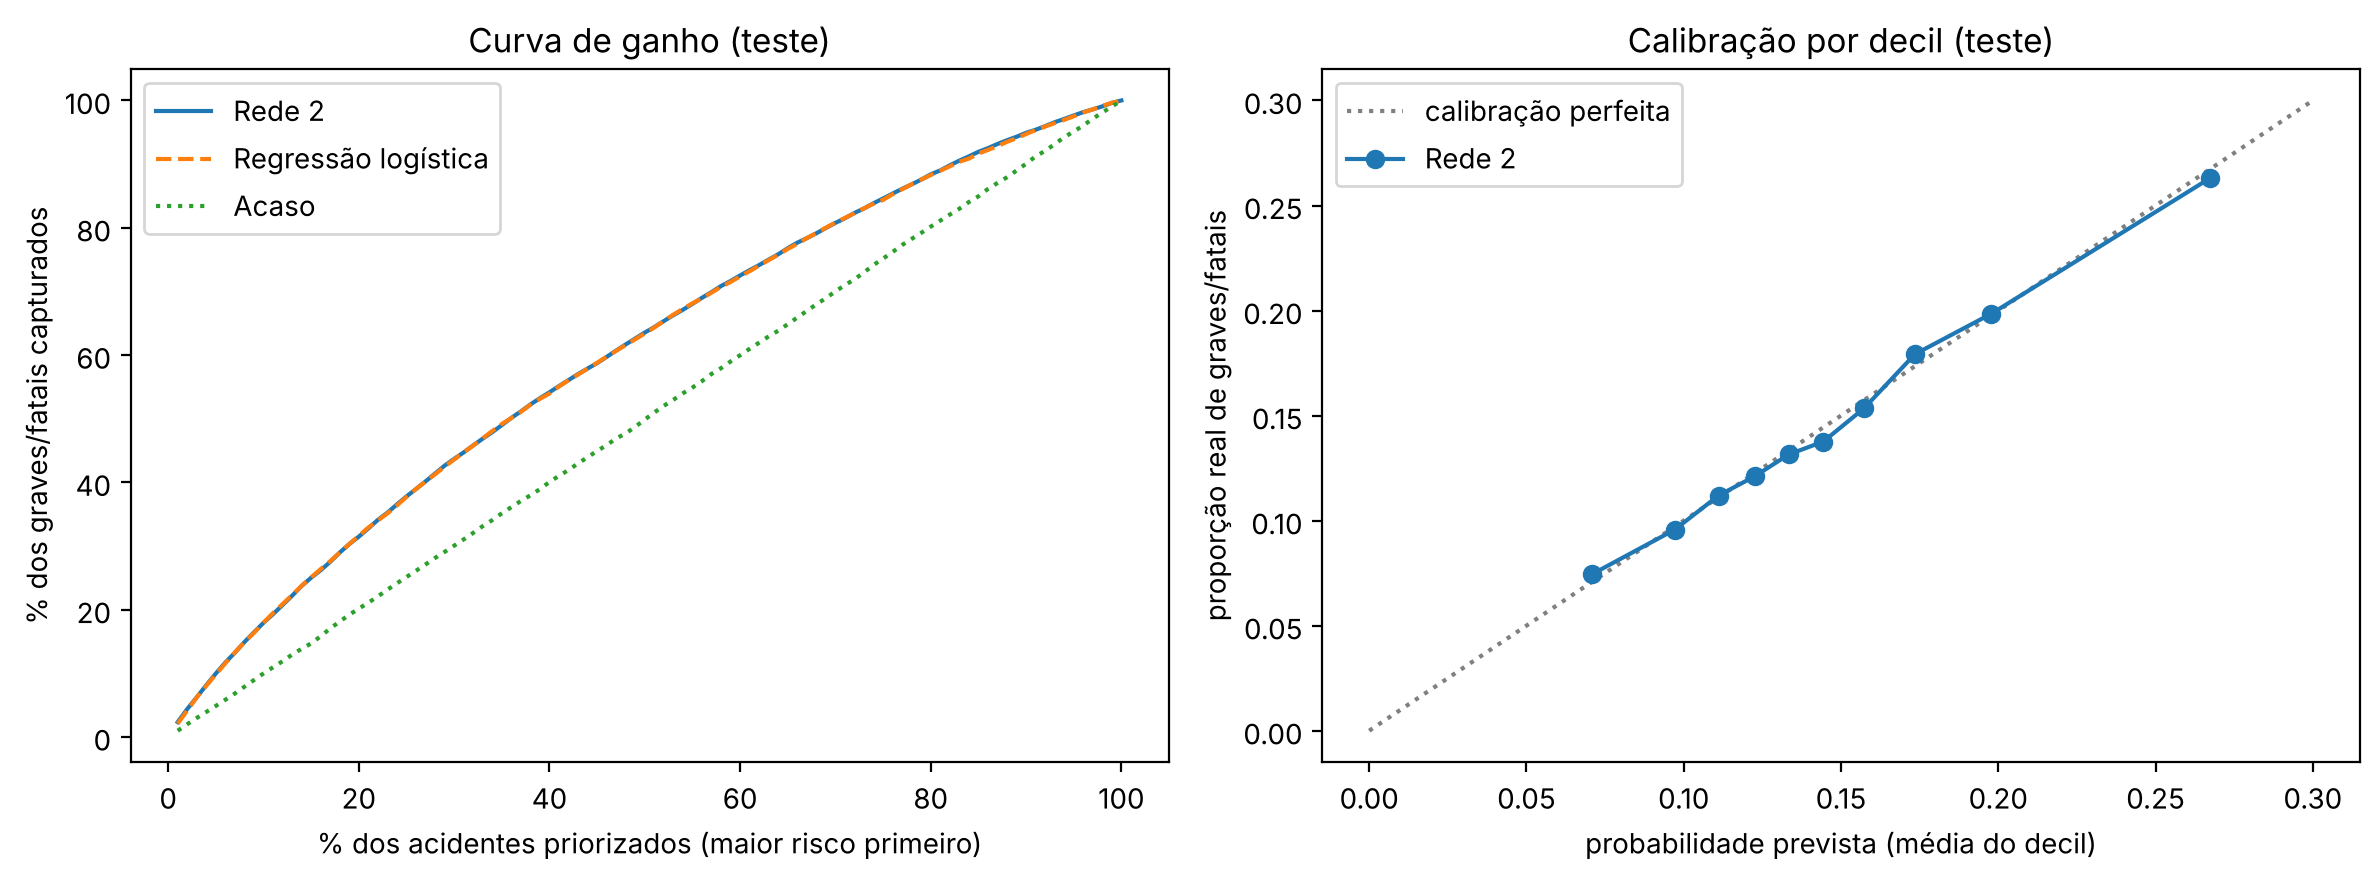

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) Curva de ganho no teste
fr = np.linspace(0.01, 1.0, 100)
for nome, s, estilo in [("Rede 2", s_rede2, "-"),
                        ("Regressão logística", s_lr, "--"),
                        ("Acaso", s_acaso, ":")]:
    ax[0].plot(fr * 100, [captura_topk_bin(yb_te, s, f) * 100 for f in fr], estilo, label=nome)
ax[0].set_xlabel("% dos acidentes priorizados (maior risco primeiro)")
ax[0].set_ylabel("% dos graves/fatais capturados")
ax[0].set_title("Curva de ganho (teste)")
ax[0].legend()

# 2) Calibração por decil
c = cal.groupby("faixa").agg(prevista=("p", "mean"), real=("y", "mean"))
ax[1].plot([0, 0.3], [0, 0.3], ":", color="gray", label="calibração perfeita")
ax[1].plot(c["prevista"], c["real"], "o-", label="Rede 2")
ax[1].set_xlabel("probabilidade prevista (média do decil)")
ax[1].set_ylabel("proporção real de graves/fatais")
ax[1].set_title("Calibração por decil (teste)")
ax[1].legend()

plt.tight_layout()
plt.savefig("ganho_calibracao.png", dpi=150)
plt.show()

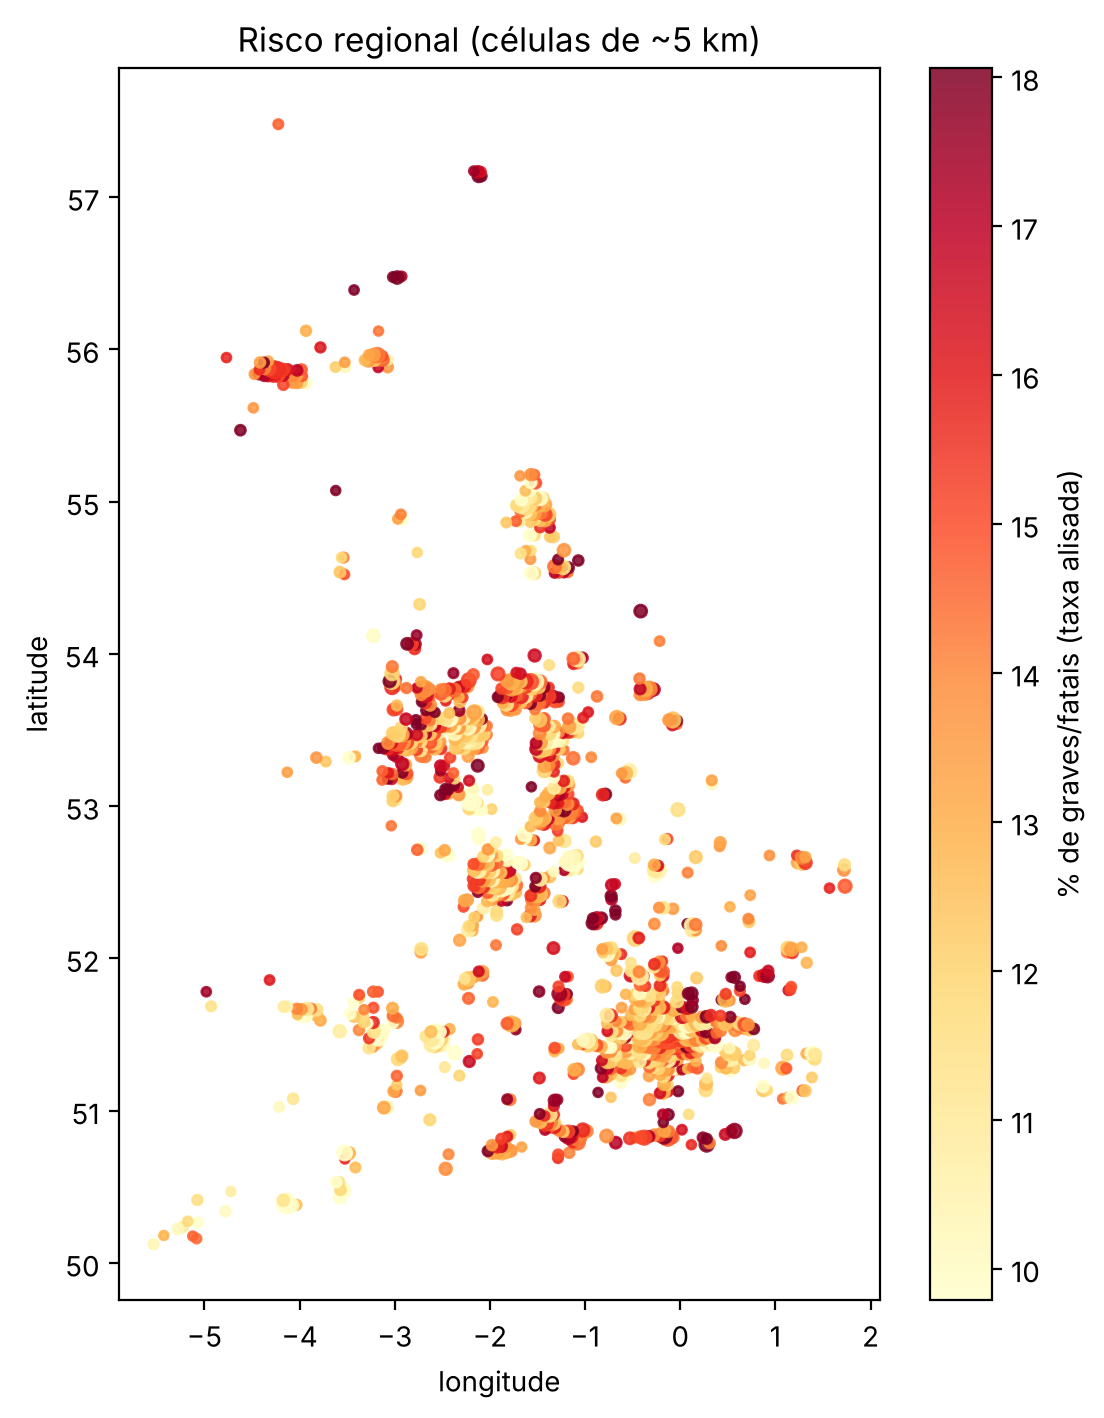

In [27]:
# 3) Mapa de risco regional: taxa alisada de graves/fatais por célula de ~5 km
todos = pd.concat([tr, va])                       # dados de treino + validação (sem o teste)
mp = todos.groupby("cel").agg(n=("grave", "size"), s=("grave", "sum"),
                              lat=("Latitude", "mean"), lon=("Longitude", "mean"))
mp = mp[mp["n"] >= 100].copy()
p0g = todos["grave"].mean()
mp["taxa"] = (mp["s"] + M * p0g) / (mp["n"] + M)

plt.figure(figsize=(6.5, 8))
sc = plt.scatter(mp["lon"], mp["lat"], c=mp["taxa"] * 100,
                 s=np.clip(np.sqrt(mp["n"]), 4, 60), cmap="YlOrRd", alpha=0.85,
                 vmin=mp["taxa"].quantile(0.05) * 100, vmax=mp["taxa"].quantile(0.95) * 100)
plt.colorbar(sc, label="% de graves/fatais (taxa alisada)")
plt.xlabel("longitude"); plt.ylabel("latitude")
plt.title("Risco regional (células de ~5 km)")
plt.gca().set_aspect(1.6)                         # corrige a distorção de longitude a ~52°N
plt.savefig("mapa_risco.png", dpi=150)
plt.show()

Interface

In [28]:
MESES = ["Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho",
         "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"]
DIAS = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]

# O usuário escolhe o distrito; usamos o centro dos acidentes dele (treino) como coordenada
dist_xy = train.groupby("District Area")[["Latitude", "Longitude"]].mean()

# Faixas de risco (decis) definidas na validação, com a taxa real de cada faixa
cortes = np.quantile(score_rede2, np.linspace(0.1, 0.9, 9))
decil_va = np.searchsorted(cortes, score_rede2) + 1        # 1 = menor risco ... 10 = maior risco
taxa_decil = pd.Series(yb_va).groupby(decil_va).mean()

def prever_risco(distrito, luz, via, area, superficie, clima, mes, dia):
    lat, lon = dist_xy.loc[distrito]
    m, dw = MESES.index(mes) + 1, DIAS.index(dia)
    cat = {"Light_Conditions": luz, "Road_Surface_Conditions": superficie,
           "Road_Type": via, "Urban_or_Rural_Area": area, "Weather_Conditions": clima,
           "Vehicle_Type": "Car",            # o modelo não usa o veículo; valor fixo
           "District Area": distrito}
    xc = torch.tensor([[maps[c][cat[c]] for c in CATS]], dtype=torch.long)
    num = [(lat - mu["Latitude"]) / sd["Latitude"], (lon - mu["Longitude"]) / sd["Longitude"],
           np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12),
           np.sin(2 * np.pi * dw / 7), np.cos(2 * np.pi * dw / 7), float(dw >= 5)]
    xn = torch.tensor([num], dtype=torch.float32)
    p = float(score_tensores(rede2, xc, xn)[0])
    faixa = int(np.searchsorted(cortes, p)) + 1
    return (f"**Probabilidade estimada de acidente grave ou fatal: {p:.1%}**\n\n"
            f"Média geral dos acidentes: {yb_tr.mean():.1%}  \n"
            f"Faixa de risco: {faixa} de 10 (10 = maior risco). Na validação, "
            f"{taxa_decil[faixa]:.1%} dos acidentes dessa faixa foram graves ou fatais.\n\n"
            "_Estimativa de risco por condições, não previsão de um acidente específico._")

# Teste: mesmo distrito, condições opostas
d0 = dist_xy.index[0]
print(d0, "\n")
print(prever_risco(d0, "Darkness - no lighting", "Single carriageway", "Rural",
                   "Wet or damp", "Fine no high winds", "Janeiro", "Sábado"), "\n")
print(prever_risco(d0, "Daylight", "Roundabout", "Urban",
                   "Dry", "Fine no high winds", "Julho", "Terça"))

Aberdeen City 

**Probabilidade estimada de acidente grave ou fatal: 30.9%**

Média geral dos acidentes: 14.7%  
Faixa de risco: 10 de 10 (10 = maior risco). Na validação, 26.6% dos acidentes dessa faixa foram graves ou fatais.

_Estimativa de risco por condições, não previsão de um acidente específico._ 

**Probabilidade estimada de acidente grave ou fatal: 11.6%**

Média geral dos acidentes: 14.7%  
Faixa de risco: 3 de 10 (10 = maior risco). Na validação, 11.3% dos acidentes dessa faixa foram graves ou fatais.

_Estimativa de risco por condições, não previsão de um acidente específico._


In [29]:
#verificação da função de predição
import re

# Taxa histórica de graves/fatais por distrito (treino)
tr_all = (train.assign(grave=(train["y"] >= 1).astype(int))
               .groupby("District Area")["grave"].agg(n="size", taxa="mean"))
print("Aberdeen City:", tr_all.loc[d0].round(3).to_dict())
grandes = tr_all[tr_all["n"] >= 1000]
print("distritos com 1000+ acidentes:", len(grandes),
      "| taxa mediana:", round(grandes["taxa"].median(), 3))
dist_baixo, dist_alto = grandes["taxa"].idxmin(), grandes["taxa"].idxmax()
print("menor taxa:", dist_baixo, round(grandes.loc[dist_baixo, "taxa"], 3),
      "| maior taxa:", dist_alto, round(grandes.loc[dist_alto, "taxa"], 3))

def prob(texto):                                # extrai a primeira porcentagem da resposta
    return float(re.search(r"([\d.]+)%", texto).group(1))

# argumentos: luz, via, área, superfície, clima, mês, dia
cenarios = {
    "escuro s/ iluminação, pista simples, rural, molhado": ("Darkness - no lighting", "Single carriageway", "Rural", "Wet or damp", "Fine no high winds", "Janeiro", "Sábado"),
    "dia, rotatória, urbano, seco":                         ("Daylight", "Roundabout", "Urban", "Dry", "Fine no high winds", "Julho", "Terça"),
    "dia, pista simples, urbano, seco":                     ("Daylight", "Single carriageway", "Urban", "Dry", "Fine no high winds", "Julho", "Terça"),
}
res = {dist: {nome: prob(prever_risco(dist, *args)) for nome, args in cenarios.items()}
       for dist in [dist_baixo, d0, dist_alto]}
pd.DataFrame(res).T

Aberdeen City: {'n': 936.0, 'taxa': 0.193}
distritos com 1000+ acidentes: 173 | taxa mediana: 0.136
menor taxa: Stoke-on-Trent 0.061 | maior taxa: Aberdeenshire 0.277


,"escuro s/ iluminação, pista simples, rural, molhado","dia, rotatória, urbano, seco","dia, pista simples, urbano, seco"
Stoke-on-Trent,12.1,3.4,6.2
Aberdeen City,30.9,11.6,19.7
Aberdeenshire,35.3,14.2,19.5


In [30]:
# Interface (Gradio). No Colab o Gradio não vem instalado.
import sys, subprocess
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

# Opções dos menus: vocabulário aprendido no treino (sem "Unknown")
DISTRITOS = sorted(dist_xy.index)
LUZ   = sorted(maps["Light_Conditions"])
VIA   = sorted(k for k in maps["Road_Type"] if k != "Unknown")
AREA  = ["Urban", "Rural"]
SUP   = sorted(k for k in maps["Road_Surface_Conditions"] if k != "Unknown")
CLIMA = sorted(k for k in maps["Weather_Conditions"] if k != "Unknown")
print(len(DISTRITOS), "distritos |", LUZ)

422 distritos | ['Darkness - lighting unknown', 'Darkness - lights lit', 'Darkness - lights unlit', 'Darkness - no lighting', 'Daylight']


In [31]:
config = dict(
    fn=prever_risco,
    inputs=[gr.Dropdown(DISTRITOS, value="Aberdeen City", label="Distrito"),
            gr.Dropdown(LUZ, value="Daylight", label="Iluminação"),
            gr.Dropdown(VIA, value="Single carriageway", label="Tipo de via"),
            gr.Dropdown(AREA, value="Urban", label="Área"),
            gr.Dropdown(SUP, value="Dry", label="Superfície da pista"),
            gr.Dropdown(CLIMA, value="Fine no high winds", label="Clima"),
            gr.Dropdown(MESES, value="Julho", label="Mês"),
            gr.Dropdown(DIAS, value="Terça", label="Dia da semana")],
    outputs=gr.Markdown(label="Risco estimado"),
    title="Risco de acidente grave no Reino Unido",
    description=("Estima, pelas condições informadas, a probabilidade de um acidente de trânsito ser "
                 "**grave ou fatal**. Ferramenta para priorizar risco, não para prever um acidente "
                 "específico. Modelo treinado com ~460 mil acidentes de 2007 a 2010 (o dataset mostra os anos como 2019 a 2022). A localização é "
                 "o centro do distrito, e o tipo de veículo não é usado."),
    examples=[["Aberdeen City", "Darkness - no lighting", "Single carriageway", "Rural",
               "Wet or damp", "Fine no high winds", "Janeiro", "Sábado"],
              ["Aberdeen City", "Daylight", "Roundabout", "Urban",
               "Dry", "Fine no high winds", "Julho", "Terça"]],
)

try:
    demo = gr.Interface(**config, flagging_mode="never")      # Gradio 5.x
except TypeError:
    demo = gr.Interface(**config, allow_flagging="never")     # Gradio 4.x

# Link público só no Colab. A versão completa do painel está em app.py (python app.py).
demo.launch(share="google.colab" in sys.modules)

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


# Experimentos extras e painel completo
Os experimentos planejados pelo grupo que não couberam neste notebook estão em `src/experimentos.py`
(resultados em `docs/resultados_experimentos.md`): correção do dia da semana, 5 sementes,
**validação temporal** (treino 2007-2009, teste 2010) e ablação com `Number_of_Vehicles`.

O painel para o usuário final (consulta + simulação, mapa e ranking, priorização de uma lista em CSV)
está em `app.py` e usa o modelo salvo por `python -m src.treinar`.